In [1]:
import sys

sys.path.append("..")

from datetime import datetime
import numpy as np
import os
from tqdm import tqdm
import matplotlib.pyplot as plt

from lib.utils import get_sample_from_json, load_transform
from classes.loader.loader import Loader
from classes.feature import LPCFeatureExtractor
from copy import deepcopy

In [2]:
PATH_TO_TRAIN_DATASET = r"../raw/sequence_2/"
PATH_TO_VALID_DATASET = r"../raw/sequence_1/"
PATH_TO_TEST_DATASET = r"../raw/sequence_3/"

# Running LPC

In [3]:
lpc_transformer = LPCFeatureExtractor(m=12)
loader = Loader(PATH_TO_TRAIN_DATASET, lpc_transformer)
dfs_per_cable = loader.load_from_folder()

  0%|          | 0/4404 [00:00<?, ?it/s]

100%|██████████| 4404/4404 [03:44<00:00, 19.60it/s]


In [4]:
p1 = dfs_per_cable["c1"].iloc[0]["features"][0,1]
p2 = dfs_per_cable["c1"].iloc[1]["features"][0,1]
p3 = dfs_per_cable["c1"].iloc[3]["features"][0,1]

In [22]:
# [0,1]

(1, 3)

In [23]:
def get_pole_info(poles) -> np.ndarray:
    return np.array([[z.real, z.imag, abs(r), f] for z, r, f in zip(poles.z, poles.r[0], poles.f)])

def get_circle(radius=1) -> np.ndarray:
    t = np.arange(0,2*np.pi,0.1)
    x = np.cos(t)
    y = np.sin(t)
    return np.array([x,y]).T

z = [get_pole_info(p[0,1]) for p in dfs_per_cable["c1"]["features"].to_numpy()]
# z1 = get_pole_info(p1)
# z2 = get_pole_info(p2)
# z3 = get_pole_info(p3)


Text(0, 0.5, 'f (Hz)')

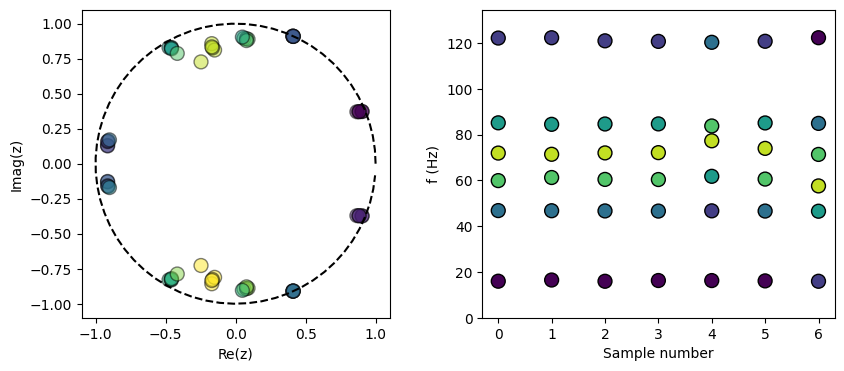

In [47]:
circle = get_circle(1)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
for k in range(5):
    plt.scatter(z[k][:,0], z[k][:,1], c=np.arange(len(z[k])), marker="o", edgecolors="k", s=100, alpha=0.5) #, s=z[k][:,2]*100)
# plt.scatter(z1[:,0], z1[:,1], c=np.arange(len(z1)), marker="o", s=z1[:,2]*100)
# plt.scatter(z2[:,0], z2[:,1], c=np.arange(len(z2)), marker="x", s=z2[:,2]*100)
# plt.scatter(z3[:,0], z3[:,1], c=np.arange(len(z3)), marker="^", s=z3[:,2]*100)
plt.plot(circle[:,0], circle[:,1], color="k", linestyle="dashed")
plt.axis("square");
plt.xlabel("Re(z)");
plt.ylabel("Imag(z)");

plt.subplot(1,2,2)
for k in range(7):
    plt.scatter([k]*len(z[k]), z[k][:,3], c=np.arange(len(z[k])), marker="o", edgecolors="k", s=100)
# plt.scatter([0]*len(z1), z1[:,3], c=np.arange(len(z1)), marker="o")
# plt.scatter([1]*len(z2), z2[:,3], c=np.arange(len(z2)), marker="x")
# plt.scatter([2]*len(z3), z3[:,3], c=np.arange(len(z2)), marker="x")
plt.ylim(bottom=0)
plt.xlabel("Sample number");
plt.ylabel("f (Hz)")

In [4]:
# lpc_transformer = LPCFeatureExtractor(m=14)
# loader = Loader(PATH_TO_TEST_DATASET, lpc_transformer)
# dfs_per_cable = loader.load_from_folder()

Text(0.5, 0, 'Sample number')

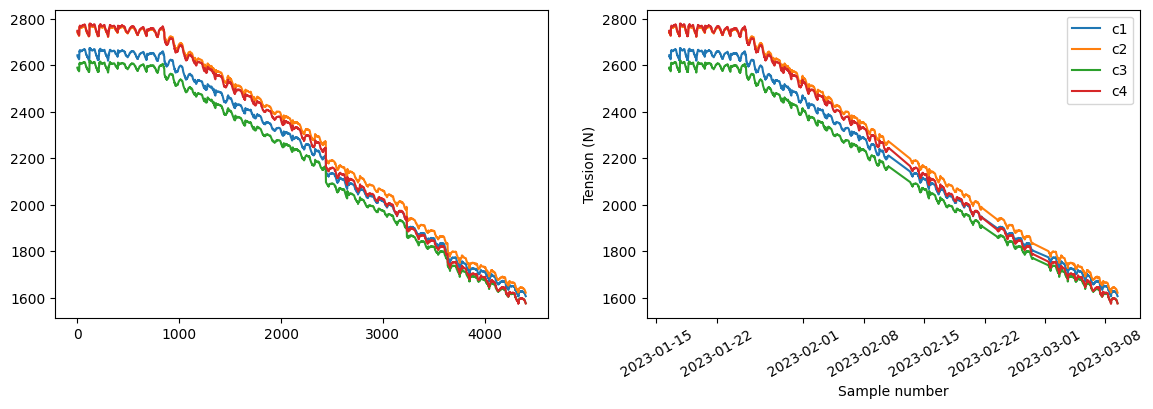

In [5]:
plt.figure(figsize=(14, 4))
for c, df in dfs_per_cable.items():
    plt.subplot(1,2,1)
    plt.plot(df.tension)
    plt.subplot(1,2,2)
    plt.plot(df.sampled_at, df.tension)

plt.legend(dfs_per_cable)
plt.xticks(rotation=30)
plt.ylabel("Tension (N)")
plt.xlabel("Sample number")

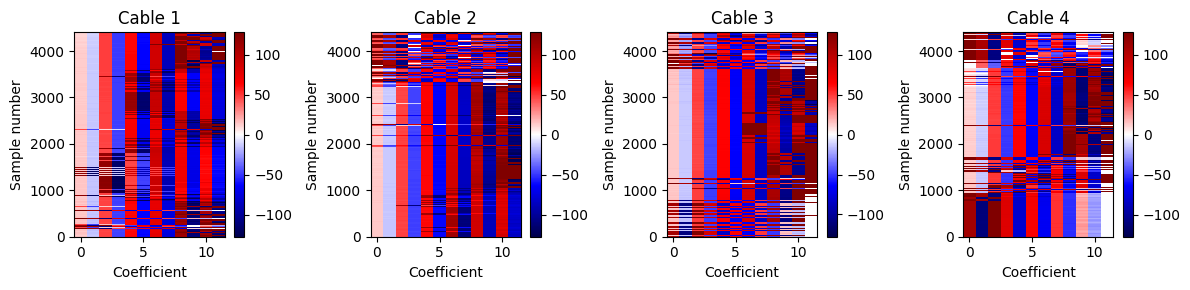

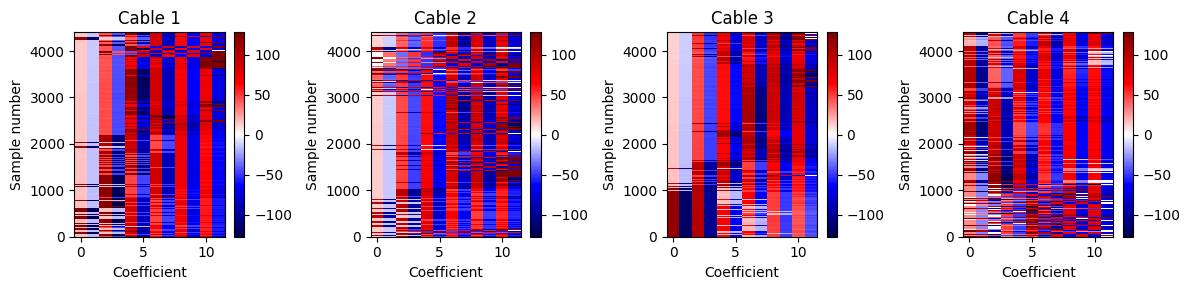

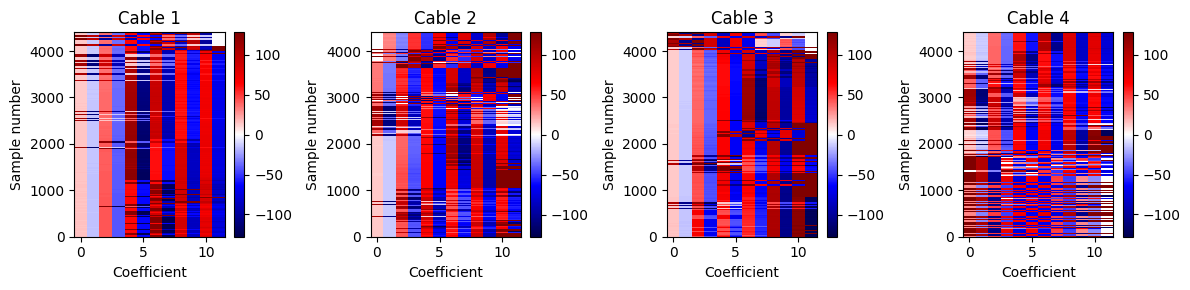

In [6]:
for axis in range(3):
    plt.figure(figsize=(12, 3))
    for c in range(4):
        feat = np.vstack(dfs_per_cable[f"c{c+1}"].features.to_list())
        x = np.arange(0, feat.shape[-1])
        plt.subplot(1, 4, c + 1)
        samples = np.arange(len(feat))
        plt.pcolormesh(x, samples, feat[:, axis, :], cmap="seismic")
        plt.xlabel("Coefficient")
        plt.ylabel("Sample number")
        plt.title(f"Cable {c+1}")
        plt.colorbar()
    plt.tight_layout()

In [17]:
i = 1
feat = np.vstack(dfs_per_cable[f"c{i}"].features.to_list())
dates = dfs_per_cable[f"c{i}"].sampled_at.to_list()

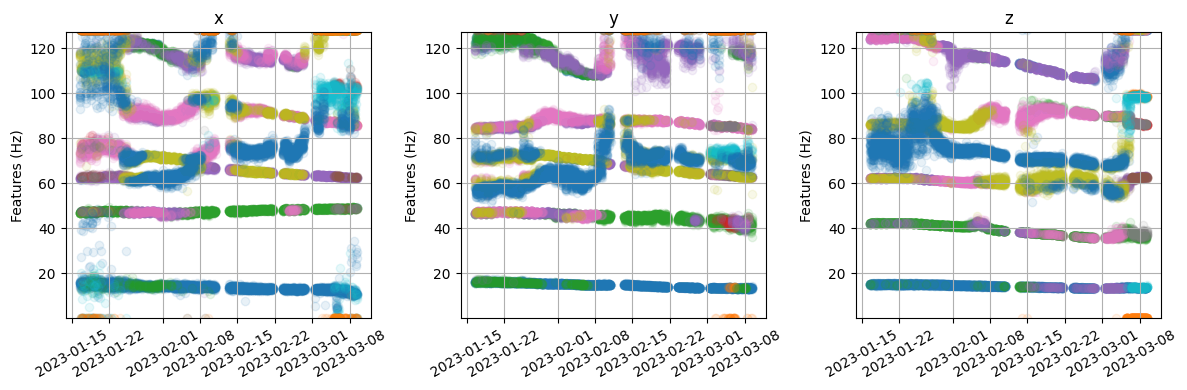

In [18]:
plt.figure(figsize=(12,4))
for i,ax in enumerate(["x","y","z"]):
    plt.subplot(1,3,i+1)
    plt.title(f"{ax}")
    for k in range(feat.shape[-1]):
        plt.scatter(dates, feat[:, i, k], alpha=0.1)
        plt.xticks(rotation=30);
    plt.ylabel("Features (Hz)")
    plt.ylim([0.1, 127])
    plt.grid()
plt.tight_layout()